In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

df = pd.read_csv("hour.csv")
print(df.head())

   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


In [2]:
print("Dimensions :", df.shape)
df.info()
print(df.isna().sum())
print(df.describe())

Dimensions : (17379, 17)
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB
instant       0
dteday        0
season 

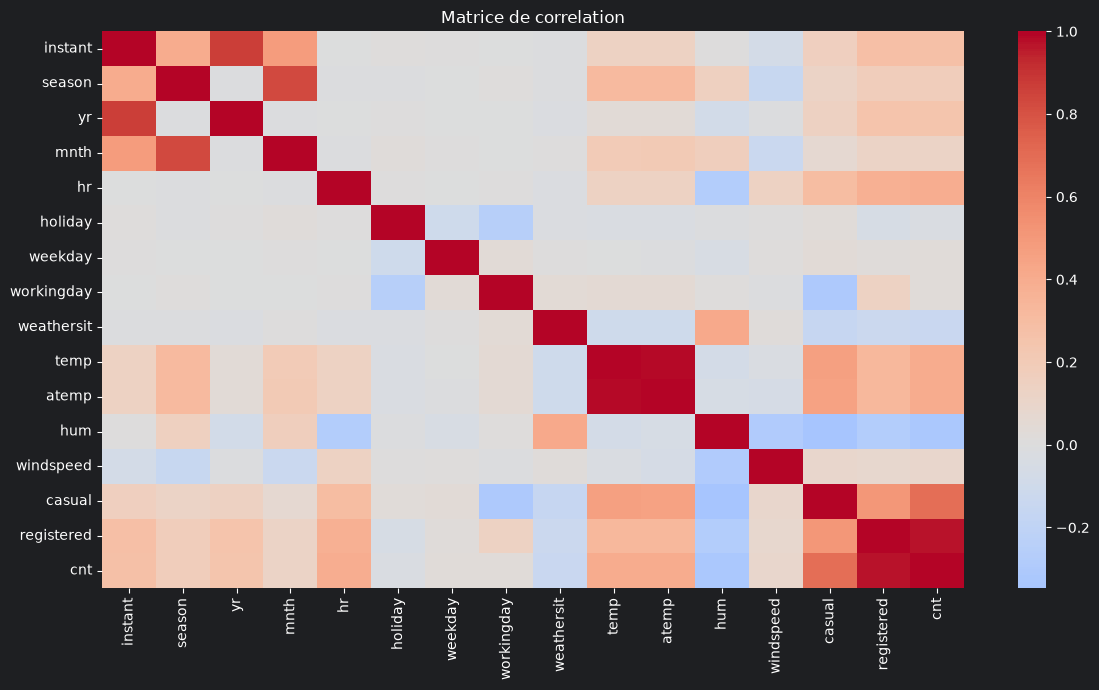

In [3]:
plt.figure(figsize=(12, 7))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Matrice de correlation")
plt.tight_layout()
plt.show()

In [4]:
df_model = df.drop(
    columns=["instant", "dteday", "casual", "registered"]
)
X = df_model.drop(columns="cnt")
y = df_model["cnt"]

In [5]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
 X_train_full, y_train_full, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [6]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
 Input(shape=(X_train_scaled.shape[1],)),
 Dense(64, activation="relu"),
 Dense(64, activation="relu"),
 Dense(32, activation="relu"),
 Dense(1)
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,105 (27.75 KB)

 Trainable params: 7,105 (27.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = EarlyStopping(
 monitor="val_loss",
 patience=15,
 restore_best_weights=True
)

history = model.fit(
 X_train_scaled, y_train,
 validation_data=(X_val_scaled, y_val),
 epochs=300,
 batch_size=32,
 callbacks=[early_stopping],
 verbose=1
)
print("Epoques effectuees :", len(history.history["loss"]))

Epoch 1/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 32017.2539 - mae: 124.6845 - val_loss: 19756.5000 - val_mae: 102.9847
Epoch 2/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 20030.5176 - mae: 103.1369 - val_loss: 18861.3789 - val_mae: 99.9852
Epoch 3/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 18493.0762 - mae: 97.5165 - val_loss: 16775.9316 - val_mae: 93.7367
Epoch 4/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 16074.5410 - mae: 89.5129 - val_loss: 14442.9502 - val_mae: 84.5115
Epoch 5/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 13986.7979 - mae: 81.5198 - val_loss: 12862.4365 - val_mae: 78.1788
Epoch 6/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12715.0596 - mae: 76.5948 - val_loss: 11967.7812 - val_mae: 74.6502
Epoch 7/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 11931.8623 - mae: 73.3375 - val_loss: 11346.7520 - val_mae: 71.7008
Epoch 8/300
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 11310.9189 - mae: 70.6780 - val_l

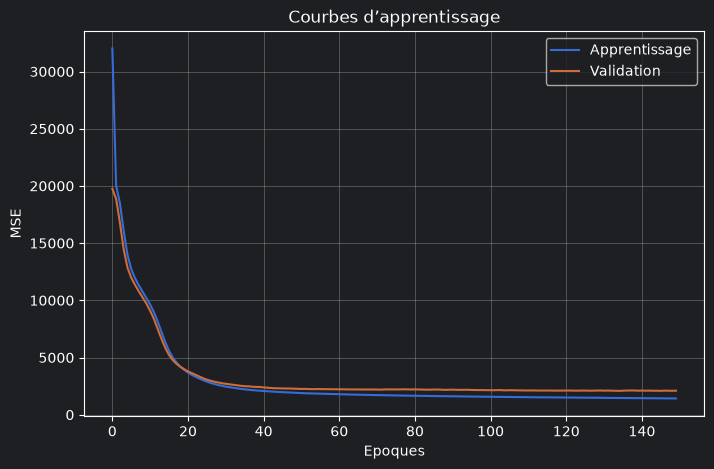

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Apprentissage")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoques")
plt.ylabel("MSE")
plt.title("Courbes d’apprentissage")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
y_pred = model.predict(X_test_scaled, verbose=0).ravel()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [10]:
print("MAE :", mae)
print("MSE :", mse)
print("R2 :", r2)

MAE : 28.35382080078125
MSE : 1977.0594482421875
R2 : 0.9375640749931335


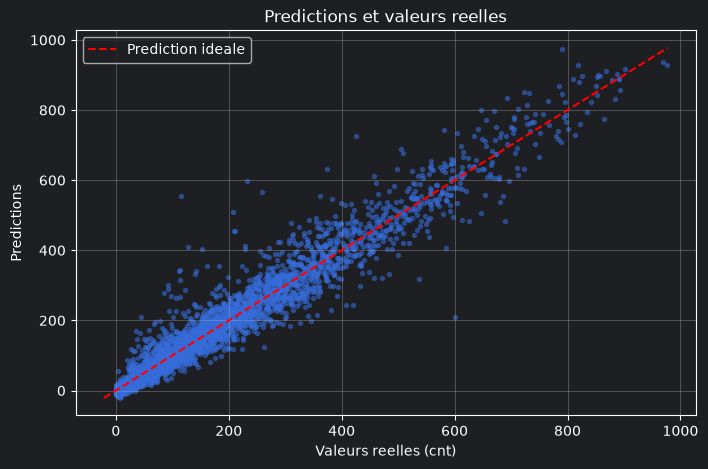

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, s=8, alpha=0.5)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Prediction ideale")
plt.xlabel("Valeurs reelles (cnt)")
plt.ylabel("Predictions")
plt.title("Predictions et valeurs reelles")
plt.legend()
plt.grid(True)
plt.show()